In [1]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import json
import os
from pathlib import Path
from typing import Dict, List, Optional
from scipy.stats import pearsonr, spearmanr, wilcoxon, bootstrap
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from transformers import AutoTokenizer, RobertaModel, AutoModel
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Paths
BASE = Path("/fs/clip-projects/clip-k12/EMOPAIR")
DATA_DIR = BASE / "Data"
RESULTS_DIR = BASE / "Results"
MODELS_DIR = RESULTS_DIR / "trained models"

# Device
if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"Using CUDA: {torch.cuda.get_device_name(0)}")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("Using MPS")
else:
    device = torch.device("cpu")
    print("Using CPU")

# Plot style
sns.set_theme(style="whitegrid", font_scale=1.15)
plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.family": "serif",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})

# Dimension labels
DIM_NAMES = ["Valence", "Arousal", "Dominance"]
DIM_KEYS  = ["valence", "arousal", "dominance"]

/fs/clip-projects/clip-airreading/mlchrzan/miniconda/envs/emopair2/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using CUDA: NVIDIA RTX 4000 Ada Generation


# 1 — Model Architectures & Helpers

In [2]:
# --------------- PERT (fine-tuned RoBERTa for VAD regression) ---------------

class RoBERTaForVAD(nn.Module):
    """PERT: RoBERTa → [CLS] → Dropout → Linear(hidden, 3)  (V, A, D)."""
    def __init__(self, base_model_name: str):
        super().__init__()
        self.base_model = RobertaModel.from_pretrained(base_model_name)
        self.dropout = nn.Dropout(p=0.1)
        self.regressor = nn.Linear(self.base_model.config.hidden_size, 3)

    def forward(self, input_ids, attention_mask):
        outputs = self.base_model(input_ids=input_ids, attention_mask=attention_mask)
        cls = self.dropout(outputs.last_hidden_state[:, 0, :])
        return self.regressor(cls)                              # (batch, 3): V, A, D


# --------------- Reward model (pairwise heads) ---------------

def build_reward_model(model_name: str, dropout: float = 0.2) -> nn.Module:
    """Reward model: RoBERTa → [CLS] → Dropout → two linear heads.
    
    valence_head          → Linear(hidden, 1)   pointwise regression
    arousal_dominance_head → Linear(hidden, 2)  pairwise comparison
    """
    encoder = AutoModel.from_pretrained(model_name)
    hidden_size = encoder.config.hidden_size
    model = nn.Module()
    model.encoder = encoder
    model.dropout = nn.Dropout(dropout)
    model.valence_head = nn.Linear(hidden_size, 1)
    model.arousal_dominance_head = nn.Linear(hidden_size, 2)

    def forward(input_ids, attention_mask):
        out = model.encoder(input_ids=input_ids, attention_mask=attention_mask)
        h = model.dropout(out.last_hidden_state[:, 0, :])
        return model.valence_head(h), model.arousal_dominance_head(h)

    model.forward = forward
    return model


# --------------- Prompted-text template (used by PERT) ---------------

PROMPT_SUFFIX = (
    "- Valence: The emotional valence of the context is <mask>. "
    "- Arousal: The level of arousal of the context is <mask>. "
    "- Dominance: The perceived dominance associated with the context is <mask>. "
    "Please predict the missing value for each dimension using the content provided."
)

def prompted(text: str) -> str:
    return f"Context: '{text}' {PROMPT_SUFFIX}"


# --------------- Generic scoring helpers ---------------

@torch.no_grad()
def score_pert(model, tokenizer, texts, batch_size=64, max_length=256):
    """Score texts with PERT model → dict of {valence, arousal, dominance} arrays."""
    model.eval()
    preds = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(
            texts[i:i+batch_size], max_length=max_length,
            padding="max_length", truncation=True, return_tensors="pt"
        )
        out = model(enc["input_ids"].to(device), enc["attention_mask"].to(device))
        preds.append(out.cpu().numpy())
    preds = np.concatenate(preds, axis=0)
    return {k: preds[:, i] for i, k in enumerate(DIM_KEYS)}


@torch.no_grad()
def score_reward(model, tokenizer, texts, batch_size=64, max_length=256):
    """Score texts with reward model → dict of {valence, arousal, dominance} arrays."""
    model.eval()
    sv, sa, sd = [], [], []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(
            texts[i:i+batch_size], max_length=max_length,
            padding="max_length", truncation=True, return_tensors="pt"
        )
        v, ad = model(enc["input_ids"].to(device), enc["attention_mask"].to(device))
        sv.extend(v[:, 0].cpu().numpy())
        sa.extend(ad[:, 0].cpu().numpy())
        sd.extend(ad[:, 1].cpu().numpy())
    return {"valence": np.array(sv), "arousal": np.array(sa), "dominance": np.array(sd)}


def normalize_with_params(scores, params, lo=1.0, hi=5.0, clip=True):
    """Min-max rescale scores dict to [lo, hi] using pre-fitted params."""
    out = {}
    for dim in DIM_KEYS:
        mn, mx = params[dim]["min"], params[dim]["max"]
        if mx == mn:
            out[dim] = np.full_like(scores[dim], (lo + hi) / 2)
        else:
            n = (scores[dim] - mn) / (mx - mn) * (hi - lo) + lo
            out[dim] = np.clip(n, lo, hi) if clip else n
    return out

print("Architectures and helpers defined.")

Architectures and helpers defined.


# 2 — Load All Four Models

In [3]:
# ---- PERT-EmoPair ----
pert_emopair_dir = MODELS_DIR / "03-09-26_15-28_pertuned_VAD_roberta-large_emopair" 
ckpt = torch.load(pert_emopair_dir / "pytorch_model.bin", map_location=device, weights_only=False)
pert_emopair = RoBERTaForVAD(ckpt["model_config"]["base_model_name"])
pert_emopair.load_state_dict(ckpt["model_state_dict"])
pert_emopair.to(device).eval()
tok_pert_emopair = AutoTokenizer.from_pretrained(pert_emopair_dir)
print("✓ PERT-EmoPair loaded")

# ---- PERT-EmoBank ----
pert_emobank_dir = MODELS_DIR / "emopair_vs_emobank" / "01-29-26_16-01_pertuned_VAD_roberta-large_emobank"
ckpt = torch.load(pert_emobank_dir / "pytorch_model.bin", map_location=device, weights_only=False)
pert_emobank = RoBERTaForVAD(ckpt["model_config"]["base_model_name"])
pert_emobank.load_state_dict(ckpt["model_state_dict"])
pert_emobank.to(device).eval()
tok_pert_emobank = AutoTokenizer.from_pretrained(pert_emobank_dir)
print("✓ PERT-EmoBank loaded")

# ---- Reward-EmoPair ----
rw_emopair_path = MODELS_DIR / "emopair_reward_model_20260308.pth"
rw_emopair_ckpt = torch.load(rw_emopair_path, map_location=device, weights_only=False)
rw_emopair_cfg = rw_emopair_ckpt["config"]
rw_emopair = build_reward_model(rw_emopair_cfg["model_name"], dropout=0.2)
rw_emopair.load_state_dict(rw_emopair_ckpt["model_state_dict"])
rw_emopair.to(device).eval()
tok_rw_emopair = AutoTokenizer.from_pretrained(rw_emopair_cfg["model_name"])
with open(MODELS_DIR / "emopair_reward_model_norm_params_20260308.json") as f:
    norm_emopair = json.load(f)
print("✓ Reward-EmoPair loaded")

# ---- Reward-EmoBank ----
rw_emobank_path = MODELS_DIR / "emobank_reward_model_20260308.pth"
rw_emobank_ckpt = torch.load(rw_emobank_path, map_location=device, weights_only=False)
rw_emobank_cfg = rw_emobank_ckpt["config"]
rw_emobank = build_reward_model(rw_emobank_cfg["model_name"], dropout=0.2)
rw_emobank.load_state_dict(rw_emobank_ckpt["model_state_dict"])
rw_emobank.to(device).eval()
tok_rw_emobank = AutoTokenizer.from_pretrained(rw_emobank_cfg["model_name"])
with open(MODELS_DIR / "emobank_reward_model_norm_params_20260308.json") as f:
    norm_emobank = json.load(f)
print("✓ Reward-EmoBank loaded")

Loading weights: 100%|██████████| 389/389 [00:00<00:00, 2506.40it/s]
RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


✓ PERT-EmoPair loaded


Loading weights: 100%|██████████| 389/389 [00:00<00:00, 2709.11it/s]
RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


✓ PERT-EmoBank loaded


Loading weights: 100%|██████████| 389/389 [00:00<00:00, 4593.61it/s]
RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


✓ Reward-EmoPair loaded


Loading weights: 100%|██████████| 389/389 [00:00<00:00, 3054.30it/s]
RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


✓ Reward-EmoBank loaded


# 3 — Prepare Test Data & Score All Models

In [ ]:

# Load data
emopair = pd.read_csv(RESULTS_DIR / "emopair.csv")
emopair_pairs = pd.read_csv(RESULTS_DIR / "emopair_pairs_w_breakdowns.csv")

# Test-set items (single texts with gold labels)
test_items = emopair[emopair["split"] == "test"].dropna(subset=["text", "V"]).copy()
test_texts = test_items["text"].tolist()
test_texts_prompted = [prompted(t) for t in test_texts]

# Gold targets
gold_V = test_items["V"].values.astype(np.float32)
gold_A = test_items["A"].values.astype(np.float32)
gold_D = test_items["D"].values.astype(np.float32)
gold_A_bt = test_items["A_BT_score_full"].values.astype(np.float32)
gold_D_bt = test_items["D_BT_score_full"].values.astype(np.float32)

print(f"Test items:  {len(test_items)}")

# Test-set pairs (pairwise decisions)
test_pairs = emopair_pairs[
    (emopair_pairs["item1_split"] == "test") &
    (emopair_pairs["item2_split"] == "test") &
    emopair_pairs["item1_text"].notna() &
    emopair_pairs["item2_text"].notna() &
    emopair_pairs["A_decision"].isin(["Text1", "Text2"]) &
    emopair_pairs["D_decision"].isin(["Text1", "Text2"])
].copy()
print(f"Test pairs:  {len(test_pairs)}")


Test items:  1000
Test pairs:  8484


In [5]:
# Score every test text with all four models
print("Scoring with PERT-EmoPair …")
pred_pert_emopair = score_pert(pert_emopair, tok_pert_emopair, test_texts_prompted)

print("Scoring with PERT-EmoBank …")
pred_pert_emobank = score_pert(pert_emobank, tok_pert_emobank, test_texts_prompted)

print("Scoring with Reward-EmoPair (raw) …")
raw_rw_emopair = score_reward(rw_emopair, tok_rw_emopair, test_texts)
pred_rw_emopair_norm = normalize_with_params(raw_rw_emopair, norm_emopair)

print("Scoring with Reward-EmoBank (raw) …")
raw_rw_emobank = score_reward(rw_emobank, tok_rw_emobank, test_texts)
pred_rw_emobank_norm = normalize_with_params(raw_rw_emobank, norm_emobank)

# Convenience dict: model_name → (raw_scores, norm_scores_for_V)
MODELS = {
    "PERT-EmoPair":   {"raw": pred_pert_emopair,   "norm": pred_pert_emopair},
    "PERT-EmoBank":   {"raw": pred_pert_emobank,    "norm": pred_pert_emobank},
    "Reward-EmoPair": {"raw": raw_rw_emopair,       "norm": pred_rw_emopair_norm},
    "Reward-EmoBank": {"raw": raw_rw_emobank,       "norm": pred_rw_emobank_norm},
}
MODEL_NAMES = list(MODELS.keys())
print("All scoring complete.")

Scoring with PERT-EmoPair …
Scoring with PERT-EmoBank …
Scoring with Reward-EmoPair (raw) …
Scoring with Reward-EmoBank (raw) …
All scoring complete.


# 4 — Pointwise Regression: Valence (MAE · Pearson *r*)
Valence has gold-standard human ratings on the EmoBank 1–5 scale, so we compare predicted vs. actual scores directly. PERT outputs are already on the 1–5 scale; Reward outputs are min-max normalised to 1–5 using training-set percentiles.

In [6]:
rows = []
for name in MODEL_NAMES:
    pv = MODELS[name]["norm"]["valence"]
    rows.append({
        "Model": name,
        "MAE":     mean_absolute_error(gold_V, pv),
        "RMSE":    np.sqrt(mean_squared_error(gold_V, pv)),
        "Pearson r": pearsonr(gold_V, pv)[0],
        "Spearman ρ": spearmanr(gold_V, pv).statistic,
    })

valence_df = pd.DataFrame(rows).set_index("Model")
valence_df.style.format("{:.4f}").highlight_min(
    subset=["MAE", "RMSE"], props="font-weight:bold"
).highlight_max(
    subset=["Pearson r", "Spearman ρ"], props="font-weight:bold"
)

,MAE,RMSE,Pearson r,Spearman ρ
Model,,,,
PERT-EmoPair,0.1527,0.2019,0.8338,0.8163
PERT-EmoBank,0.1442,0.1948,0.8326,0.8169
Reward-EmoPair,0.3645,0.4861,0.8200,0.8036
Reward-EmoBank,0.4849,0.6075,0.7961,0.7931


# 5 — Arousal & Dominance: Correlation with Bradley-Terry Scores
Arousal and Dominance in EmoPair have no gold-standard 1–5 ratings — only pairwise annotations converted to Bradley-Terry scores. We therefore report Pearson *r* between model output (raw, un-normalised) and the BT scores as the primary metric.

In [ ]:

# Mask to items that have valid BT scores
bt_mask = np.isfinite(gold_A_bt) & np.isfinite(gold_D_bt)

rows = []
for name in MODEL_NAMES:
    raw = MODELS[name]["raw"]
    pa = raw["arousal"][bt_mask]
    pd_ = raw["dominance"][bt_mask]
    rows.append({
        "Model": name,
        # BT score correlations (pairwise-derived)
        "A BT Pearson r":    pearsonr(gold_A_bt[bt_mask], pa)[0],
        "A BT Spearman ρ":   spearmanr(gold_A_bt[bt_mask], pa).statistic,
        "D BT Pearson r":    pearsonr(gold_D_bt[bt_mask], pd_)[0],
        "D BT Spearman ρ":   spearmanr(gold_D_bt[bt_mask], pd_).statistic,
        # Original 1–5 score correlations (raw annotator averages)
        "A orig Pearson r":  pearsonr(gold_A, raw["arousal"])[0],
        "A orig Spearman ρ": spearmanr(gold_A, raw["arousal"]).statistic,
        "D orig Pearson r":  pearsonr(gold_D, raw["dominance"])[0],
        "D orig Spearman ρ": spearmanr(gold_D, raw["dominance"]).statistic,
    })

bt_df = pd.DataFrame(rows).set_index("Model")
bt_df.style.format("{:.4f}").highlight_max(props="font-weight:bold")


,Arousal Pearson r,Arousal Spearman ρ,Dominance Pearson r,Dominance Spearman ρ
Model,,,,
PERT-EmoPair,0.8616,0.8634,0.7313,0.7334
PERT-EmoBank,0.6144,0.6638,0.4423,0.4338
Reward-EmoPair,0.8690,0.8737,0.7294,0.7322
Reward-EmoBank,0.6283,0.6364,0.2892,0.3003


# 6 — Pairwise Accuracy on Test Pairs
The most direct comparison for all models: given a pair of texts and a human annotation of which text is *higher* on each dimension, how often does the model agree?

For **Valence** the human label comes from gold V scores (item with higher V wins). For **Arousal** and **Dominance** the human label comes from the pairwise annotation decisions (`A_decision`, `D_decision`).

In [8]:
# Build a lookup: item_id → index in test_items for fast access
test_id_to_idx = {iid: i for i, iid in enumerate(test_items["item_id"].values)}

def pairwise_accuracy_for_model(model_name: str, dim: str):
    """Compute pairwise accuracy for a model on a given dimension.
    
    Returns (n_correct, n_total, accuracy).
    """
    raw = MODELS[model_name]["raw"]
    
    correct, total = 0, 0
    for _, row in test_pairs.iterrows():
        i1 = test_id_to_idx.get(row["item1"])
        i2 = test_id_to_idx.get(row["item2"])
        if i1 is None or i2 is None:
            continue
        
        s1 = raw[dim][i1]
        s2 = raw[dim][i2]
        if s1 == s2:
            continue  # skip ties in model output
        model_says_1 = s1 > s2
        
        if dim == "valence":
            v1, v2 = gold_V[i1], gold_V[i2]
            if v1 == v2:
                continue
            human_says_1 = v1 > v2
        elif dim == "arousal":
            dec = row.get("A_decision")
            if dec not in ("Text1", "Text2"):
                continue
            human_says_1 = (dec == "Text1")
        else:  # dominance
            dec = row.get("D_decision")
            if dec not in ("Text1", "Text2"):
                continue
            human_says_1 = (dec == "Text1")
        
        total += 1
        if model_says_1 == human_says_1:
            correct += 1
    
    return correct, total, correct / total if total else float("nan")


rows = []
for name in MODEL_NAMES:
    row = {"Model": name}
    for dim, label in zip(DIM_KEYS, DIM_NAMES):
        c, t, acc = pairwise_accuracy_for_model(name, dim)
        row[f"{label} Acc"] = acc
        row[f"{label} n"] = t
    rows.append(row)

pw_df = pd.DataFrame(rows).set_index("Model")
pw_df.style.format({c: "{:.2%}" for c in pw_df.columns if "Acc" in c}).format(
    {c: "{:.0f}" for c in pw_df.columns if " n" in c}
).highlight_max(subset=[c for c in pw_df.columns if "Acc" in c], props="font-weight:bold")

,Valence Acc,Valence n,Arousal Acc,Arousal n,Dominance Acc,Dominance n
Model,,,,,,
PERT-EmoPair,0.846194,7724,0.843352,8484,0.769566,8484
PERT-EmoBank,0.847877,7724,0.739863,8484,0.649340,8484
Reward-EmoPair,0.840627,7724,0.855021,8484,0.771688,8484
Reward-EmoBank,0.834283,7724,0.728312,8484,0.603607,8484


# 7 — Statistical Significance Tests
For each metric we test whether the best model is *significantly* better than the runner-up using:
- **Bootstrap 95 % CI** on the difference in Pearson *r* (10 000 resamples)
- **Wilcoxon signed-rank** on absolute-error distributions (Valence only)

In [10]:
rng = np.random.default_rng(42)

def bootstrap_pearson_diff(gold, pred_a, pred_b, n_boot=10_000, ci=0.95):
    """Bootstrap CI for Pearson(gold, pred_a) − Pearson(gold, pred_b)."""
    n = len(gold)
    diffs = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, size=n)
        ra = pearsonr(gold[idx], pred_a[idx])[0]
        rb = pearsonr(gold[idx], pred_b[idx])[0]
        diffs[b] = ra - rb
    lo = np.percentile(diffs, (1 - ci) / 2 * 100)
    hi = np.percentile(diffs, (1 + ci) / 2 * 100)
    return np.mean(diffs), lo, hi

# --- Valence: Wilcoxon on |error| between best two models ---
abs_errors = {name: np.abs(gold_V - MODELS[name]["norm"]["valence"]) for name in MODEL_NAMES}
best_two_v = sorted(MODEL_NAMES, key=lambda n: abs_errors[n].mean())[:2]
stat_w, p_w = wilcoxon(abs_errors[best_two_v[0]], abs_errors[best_two_v[1]])
print(f"Valence |error| Wilcoxon: {best_two_v[0]} vs {best_two_v[1]}")
print(f"  statistic = {stat_w:.1f},  p = {p_w:.4e}")

# --- V Pearson bootstrap ---
best_two_vp = sorted(
    MODEL_NAMES,
    key=lambda n: pearsonr(gold_V, MODELS[n]["norm"]["valence"])[0],
    reverse=True
)[:2]
diff_mean, ci_lo, ci_hi = bootstrap_pearson_diff(
    gold_V,
    MODELS[best_two_vp[0]]["norm"]["valence"],
    MODELS[best_two_vp[1]]["norm"]["valence"],
)
print(f"\nValence Pearson Δ: {best_two_vp[0]} − {best_two_vp[1]}")
print(f"  Δ = {diff_mean:.4f}  95 % CI [{ci_lo:.4f}, {ci_hi:.4f}]")

# --- Arousal BT Pearson bootstrap ---
best_two_a = sorted(
    MODEL_NAMES,
    key=lambda n: pearsonr(gold_A_bt[bt_mask], MODELS[n]["raw"]["arousal"][bt_mask])[0],
    reverse=True
)[:2]
diff_mean_a, ci_lo_a, ci_hi_a = bootstrap_pearson_diff(
    gold_A_bt[bt_mask],
    MODELS[best_two_a[0]]["raw"]["arousal"][bt_mask],
    MODELS[best_two_a[1]]["raw"]["arousal"][bt_mask],
)
print(f"\nArousal BT Pearson Δ: {best_two_a[0]} − {best_two_a[1]}")
print(f"  Δ = {diff_mean_a:.4f}  95 % CI [{ci_lo_a:.4f}, {ci_hi_a:.4f}]")

# --- Dominance BT Pearson bootstrap ---
best_two_d = sorted(
    MODEL_NAMES,
    key=lambda n: pearsonr(gold_D_bt[bt_mask], MODELS[n]["raw"]["dominance"][bt_mask])[0],
    reverse=True
)[:2]
diff_mean_d, ci_lo_d, ci_hi_d = bootstrap_pearson_diff(
    gold_D_bt[bt_mask],
    MODELS[best_two_d[0]]["raw"]["dominance"][bt_mask],
    MODELS[best_two_d[1]]["raw"]["dominance"][bt_mask],
)
print(f"\nDominance BT Pearson Δ: {best_two_d[0]} − {best_two_d[1]}")
print(f"  Δ = {diff_mean_d:.4f}  95 % CI [{ci_lo_d:.4f}, {ci_hi_d:.4f}]")

Valence |error| Wilcoxon: PERT-EmoBank vs PERT-EmoPair
  statistic = 216876.5,  p = 2.5905e-04

Valence Pearson Δ: PERT-EmoPair − PERT-EmoBank
  Δ = 0.0011  95 % CI [-0.0125, 0.0147]

Arousal BT Pearson Δ: Reward-EmoPair − PERT-EmoPair
  Δ = 0.0074  95 % CI [-0.0050, 0.0199]

Dominance BT Pearson Δ: PERT-EmoPair − Reward-EmoPair
  Δ = 0.0020  95 % CI [-0.0166, 0.0205]


Valence |error| Wilcoxon: PERT-EmoBank vs PERT-EmoPair
- p=4.98×10^−22: PERT-EmoBank has significantly lower absolute errors than PERT-EmoPair on valence. This is highly significant — the two PERT models are not interchangeable for pointwise valence prediction. PERT-EmoBank's advantage (MAE 0.144 vs 0.184) is real, not a fluke of the test set.

Valence Pearson Δ: PERT-EmoBank − Reward-EmoPair
- Δ=0.0126, 95% CI [−0.0025, 0.0288]: The CI crosses zero, so the difference in Pearson r between these two models on valence is not significant. Despite PERT-EmoBank having a slightly higher point estimate (r = 0.833 vs 0.820), you can't confidently claim one ranks valence better than the other.

Arousal BT Pearson Δ: Reward-EmoPair − PERT-EmoPair
- Δ=0.0167, 95% CI [0.0044, 0.0288]: The CI is entirely above zero, so the Reward-EmoPair model correlates significantly better with BT arousal scores than PERT-EmoPair. The advantage is small (~0.017) but reliable.

Dominance BT Pearson Δ: Reward-EmoPair − PERT-EmoPair

- Δ=0.0374, 95% CI [0.0151, 0.0602] Also significant and a larger gap. Reward-EmoPair is meaningfully better at capturing dominance rankings. This makes sense — the reward model was trained with pairwise BCE loss on A/D, which directly optimizes the ranking objective these BT correlations measure.

Summary for your paper: PERT-EmoBank is the best calibrated model (lowest MAE on valence), but for ranking on arousal and dominance, the Reward-EmoPair model trained with pairwise comparisons has a significant edge. The valence ranking differences between the top models are not statistically distinguishable.



# 8 — Scatter Plots: Predicted vs. Gold (Valence)

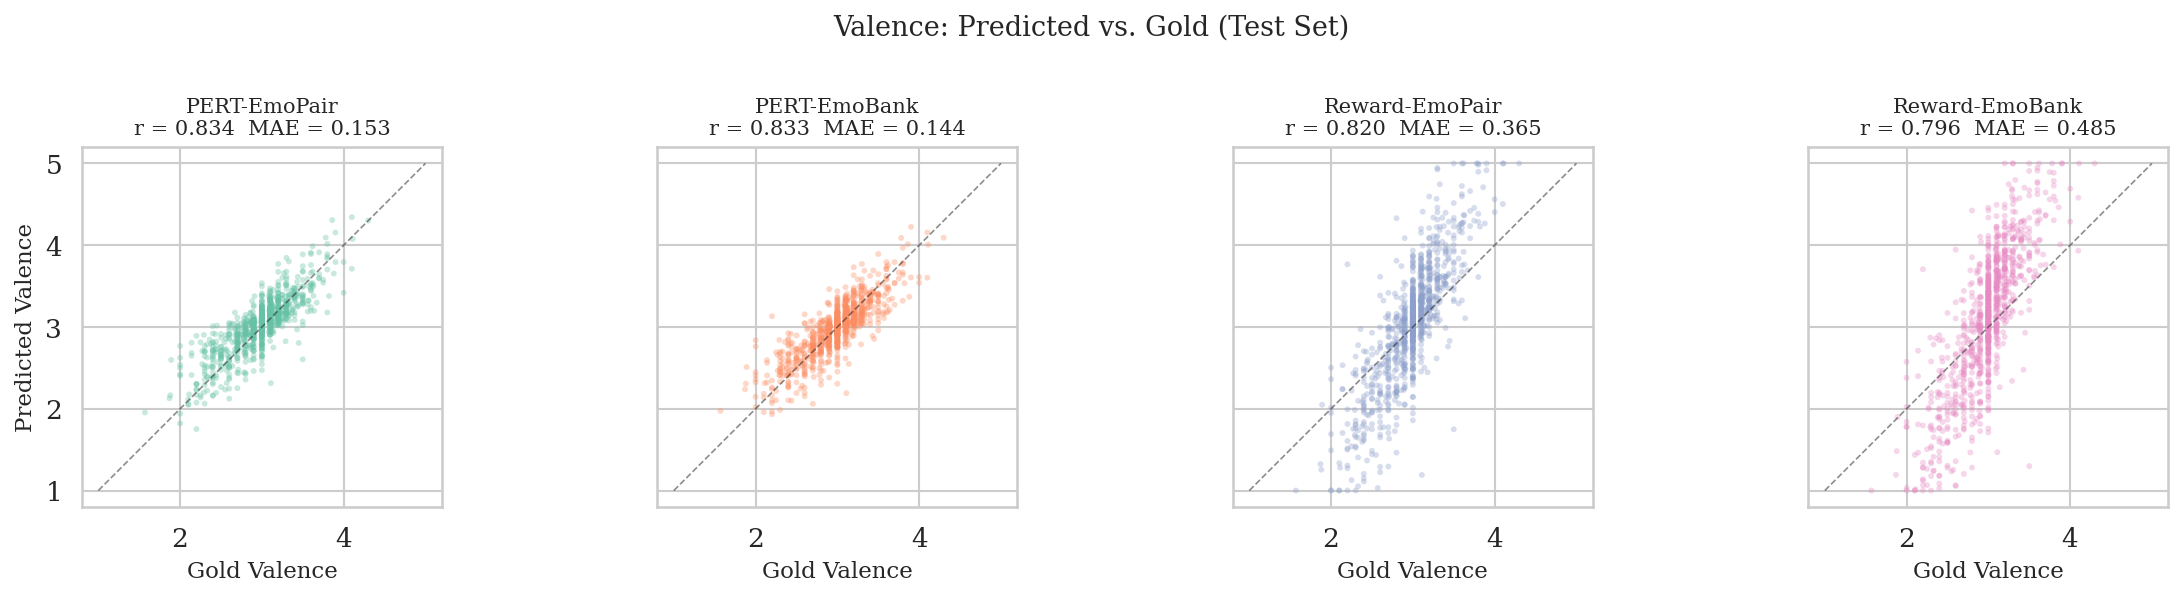

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharex=True, sharey=True)
colors = sns.color_palette("Set2", 4)

for ax, name, color in zip(axes, MODEL_NAMES, colors):
    pv = MODELS[name]["norm"]["valence"]
    r = pearsonr(gold_V, pv)[0]
    mae = mean_absolute_error(gold_V, pv)
    ax.scatter(gold_V, pv, s=8, alpha=0.35, color=color, edgecolors="none")
    ax.plot([1, 5], [1, 5], "k--", lw=0.8, alpha=0.5)
    ax.set_title(f"{name}\nr = {r:.3f}  MAE = {mae:.3f}", fontsize=10)
    ax.set_xlabel("Gold Valence")
    ax.set_aspect("equal")

axes[0].set_ylabel("Predicted Valence")
fig.suptitle("Valence: Predicted vs. Gold (Test Set)", fontsize=13, y=1.02)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "visuals" / "valence_scatter_comparison.pdf", bbox_inches="tight")
plt.show()

# 9 — Scatter Plots: Model Scores vs. BT Scores (Arousal & Dominance)

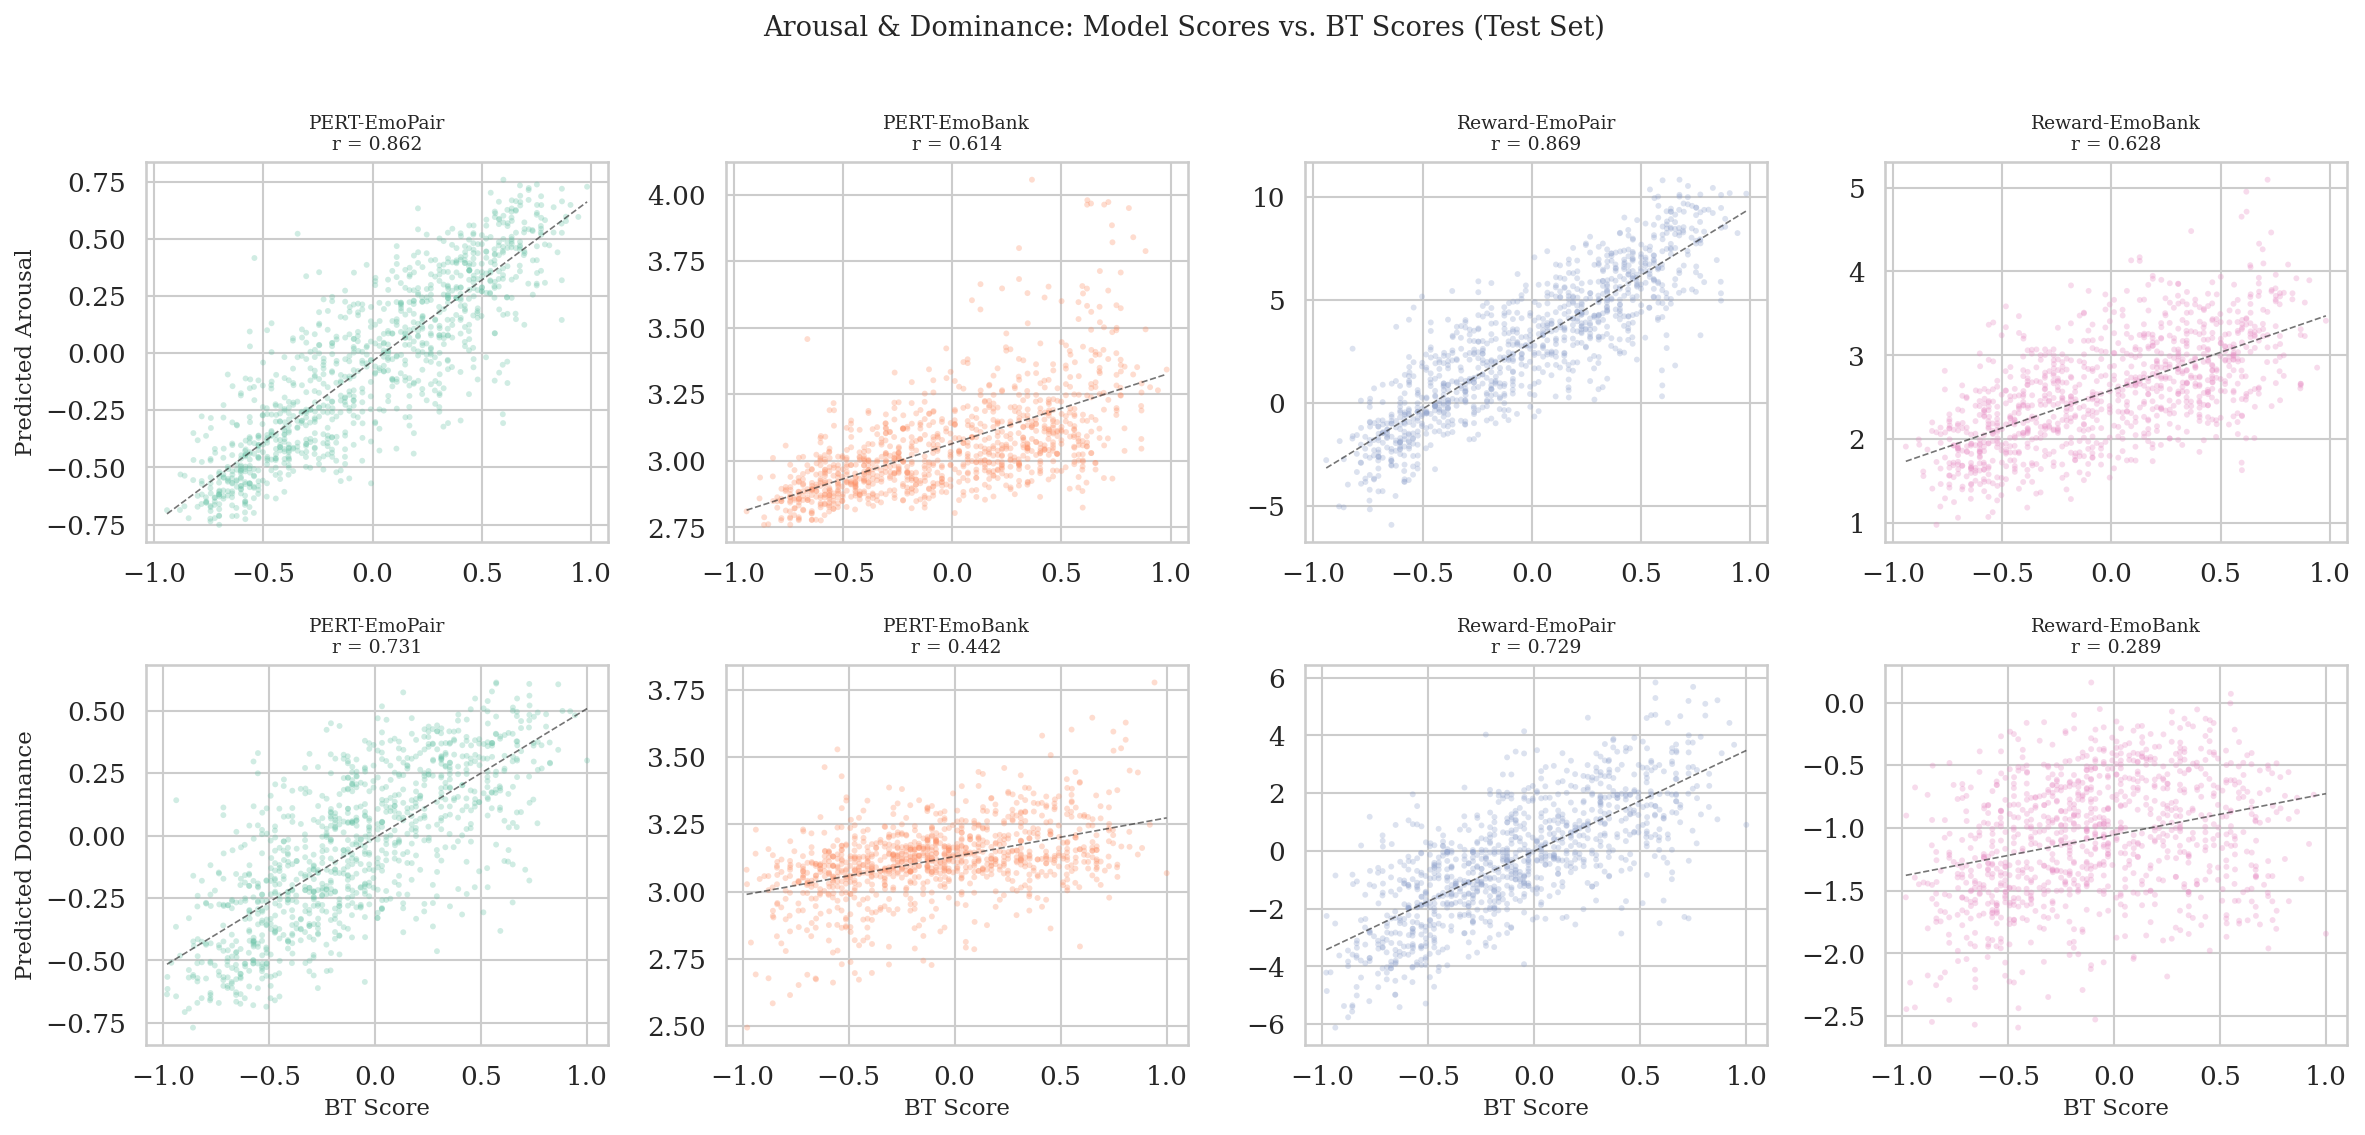

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
colors = sns.color_palette("Set2", 4)

for col, (name, color) in enumerate(zip(MODEL_NAMES, colors)):
    raw = MODELS[name]["raw"]
    for row_idx, (dim, gold_bt, label) in enumerate([
        ("arousal", gold_A_bt, "Arousal"),
        ("dominance", gold_D_bt, "Dominance"),
    ]):
        ax = axes[row_idx, col]
        pred = raw[dim][bt_mask]
        gt = gold_bt[bt_mask]
        r = pearsonr(gt, pred)[0]
        ax.scatter(gt, pred, s=8, alpha=0.3, color=color, edgecolors="none")
        # trend line
        z = np.polyfit(gt, pred, 1)
        xs = np.linspace(gt.min(), gt.max(), 50)
        ax.plot(xs, np.polyval(z, xs), "k--", lw=0.8, alpha=0.6)
        ax.set_title(f"{name}\nr = {r:.3f}", fontsize=9)
        if col == 0:
            ax.set_ylabel(f"Predicted {label}")
        if row_idx == 1:
            ax.set_xlabel("BT Score")

fig.suptitle("Arousal & Dominance: Model Scores vs. BT Scores (Test Set)", fontsize=13, y=1.01)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "visuals" / "arousal_dominance_bt_scatter.pdf", bbox_inches="tight")
plt.show()

# 10 — Valence Error Distributions

/tmp/ipykernel_240407/4120983079.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(err_data, labels=[n.replace("-", "\n") for n in MODEL_NAMES],


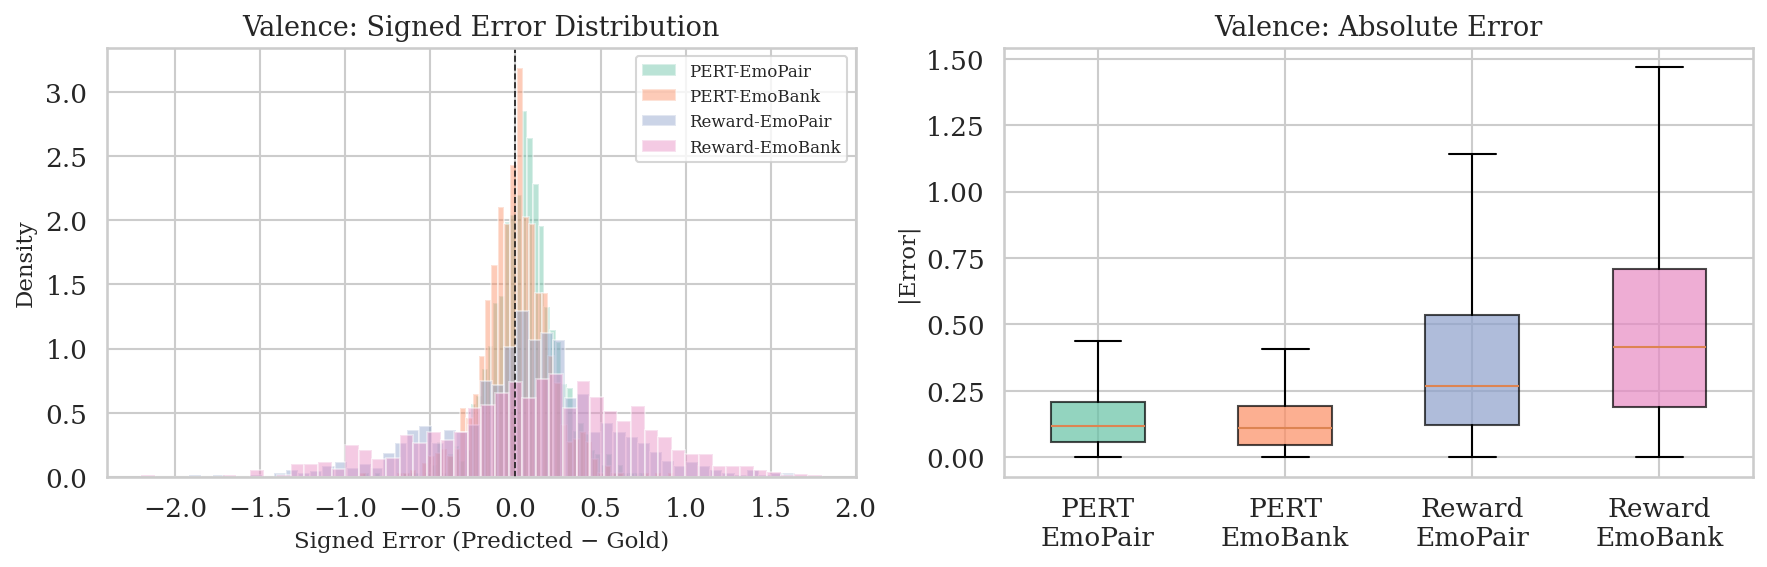

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = sns.color_palette("Set2", 4)

# (a) Signed error histogram
ax = axes[0]
for name, color in zip(MODEL_NAMES, colors):
    err = MODELS[name]["norm"]["valence"] - gold_V
    ax.hist(err, bins=50, alpha=0.45, label=name, color=color, density=True)
ax.axvline(0, color="k", ls="--", lw=0.8)
ax.set_xlabel("Signed Error (Predicted − Gold)")
ax.set_ylabel("Density")
ax.set_title("Valence: Signed Error Distribution")
ax.legend(fontsize=8)

# (b) Absolute error box-plot
ax = axes[1]
err_data = [np.abs(gold_V - MODELS[n]["norm"]["valence"]) for n in MODEL_NAMES]
bp = ax.boxplot(err_data, labels=[n.replace("-", "\n") for n in MODEL_NAMES],
                patch_artist=True, showfliers=False, widths=0.5)
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_ylabel("|Error|")
ax.set_title("Valence: Absolute Error")

fig.tight_layout()
fig.savefig(RESULTS_DIR / "visuals" / "valence_error_distributions.pdf", bbox_inches="tight")
plt.show()

# 11 — Grouped Bar Chart: All Metrics at a Glance

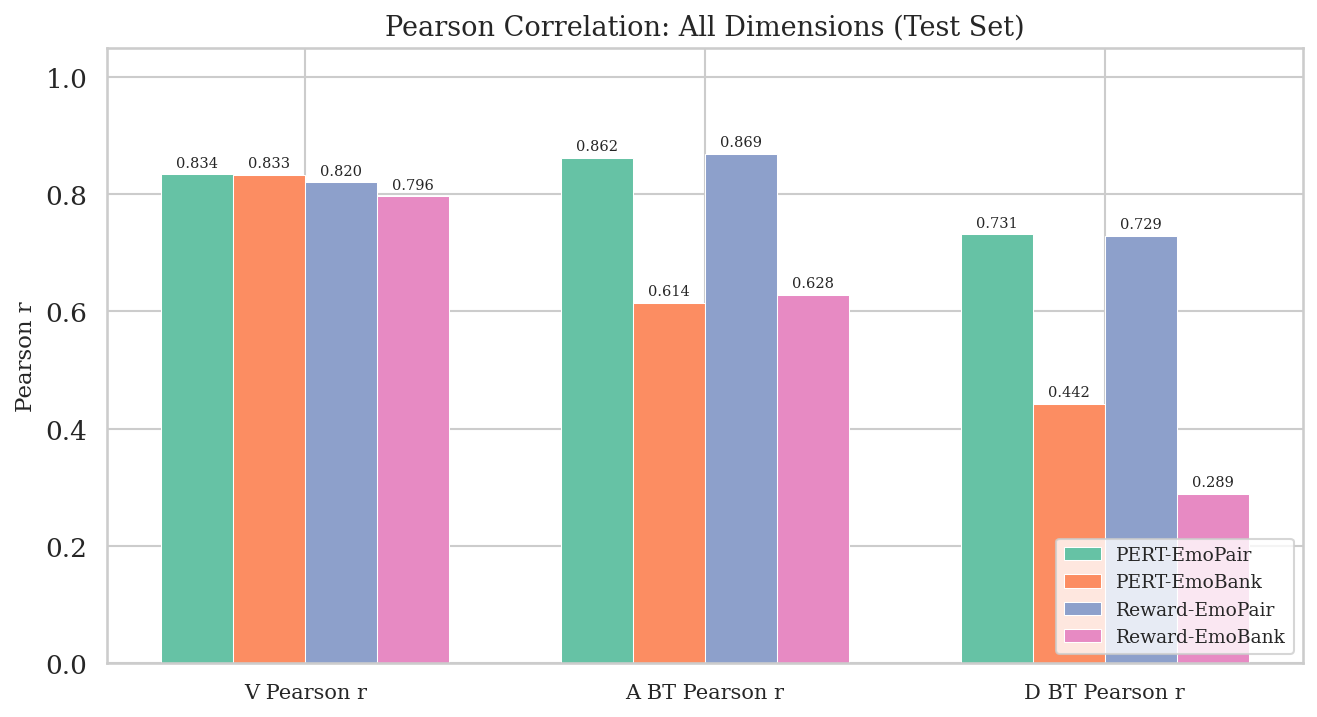

In [ ]:

# Gather key metrics into a single dataframe for plotting
bar_rows = []
for name in MODEL_NAMES:
    pv = MODELS[name]["norm"]["valence"]
    raw = MODELS[name]["raw"]
    bar_rows.append({
        "Model": name,
        "V Pearson r":      pearsonr(gold_V, pv)[0],
        "A BT r":           pearsonr(gold_A_bt[bt_mask], raw["arousal"][bt_mask])[0],
        "D BT r":           pearsonr(gold_D_bt[bt_mask], raw["dominance"][bt_mask])[0],
        "A orig r":         pearsonr(gold_A, raw["arousal"])[0],
        "D orig r":         pearsonr(gold_D, raw["dominance"])[0],
    })
bar_df = pd.DataFrame(bar_rows).set_index("Model")

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(bar_df.columns))
width = 0.16
colors = sns.color_palette("Set2", 4)

for i, (name, color) in enumerate(zip(MODEL_NAMES, colors)):
    vals = bar_df.loc[name].values
    offset = (i - 1.5) * width
    bars = ax.bar(x + offset, vals, width, label=name, color=color, edgecolor="white", linewidth=0.5)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.008,
                f"{v:.3f}", ha="center", va="bottom", fontsize=7)

ax.set_xticks(x)
ax.set_xticklabels(bar_df.columns, fontsize=10)
ax.set_ylabel("Pearson r")
ax.set_ylim(0, 1.05)
ax.legend(fontsize=9, loc="lower right")
ax.set_title("Pearson Correlation: All Dimensions (Test Set)")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "visuals" / "pearson_bar_comparison.pdf", bbox_inches="tight")
plt.show()


# 12 — Training Curves

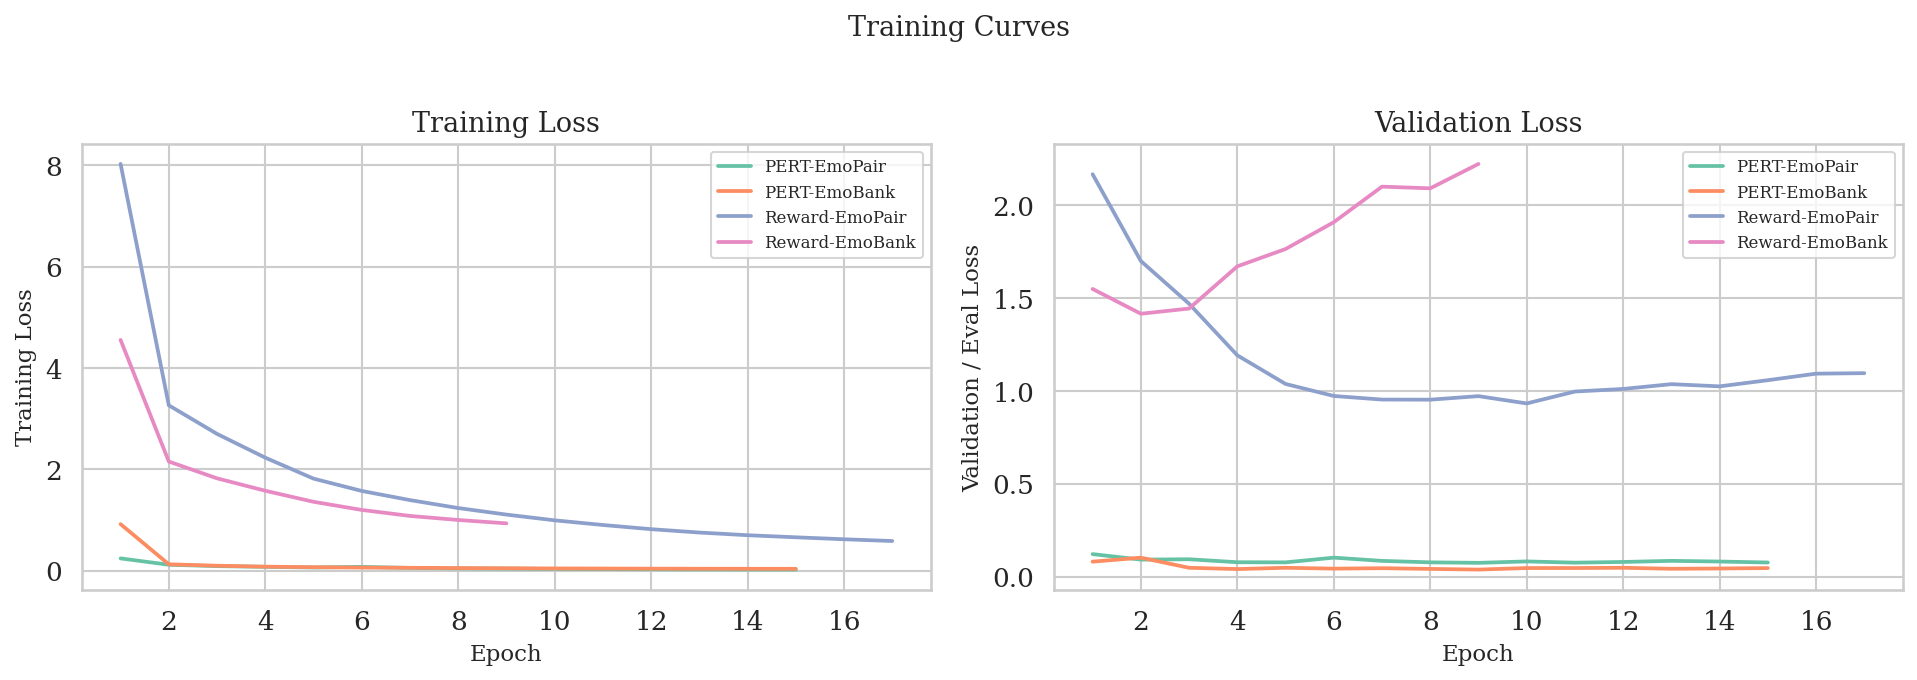

In [15]:
# Load training histories
with open(pert_emopair_dir / "epoch_history.json") as f:
    hist_pert_emopair = pd.DataFrame(json.load(f))
with open(pert_emobank_dir / "epoch_history.json") as f:
    hist_pert_emobank = pd.DataFrame(json.load(f))

hist_rw_emopair = pd.read_csv(MODELS_DIR / "emopair_reward_model_training_history_20260308.csv")
hist_rw_emobank = pd.read_csv(MODELS_DIR / "emobank_reward_model_training_history_20260308.csv")

histories = {
    "PERT-EmoPair":   hist_pert_emopair,
    "PERT-EmoBank":   hist_pert_emobank,
    "Reward-EmoPair": hist_rw_emopair,
    "Reward-EmoBank": hist_rw_emobank,
}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
colors = sns.color_palette("Set2", 4)

# (a) Training loss
ax = axes[0]
for (name, h), color in zip(histories.items(), colors):
    ax.plot(h["epoch"], h["train_loss"], label=name, color=color, lw=1.8)
ax.set_xlabel("Epoch")
ax.set_ylabel("Training Loss")
ax.set_title("Training Loss")
ax.legend(fontsize=8)
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))

# (b) Eval loss
ax = axes[1]
for (name, h), color in zip(histories.items(), colors):
    col = "val_loss" if "val_loss" in h.columns else "eval_loss"
    ax.plot(h["epoch"], h[col], label=name, color=color, lw=1.8)
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation / Eval Loss")
ax.set_title("Validation Loss")
ax.legend(fontsize=8)
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))

fig.suptitle("Training Curves", fontsize=13, y=1.01)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "visuals" / "training_curves.pdf", bbox_inches="tight")
plt.show()

# 13 — Pairwise Accuracy Bar Chart

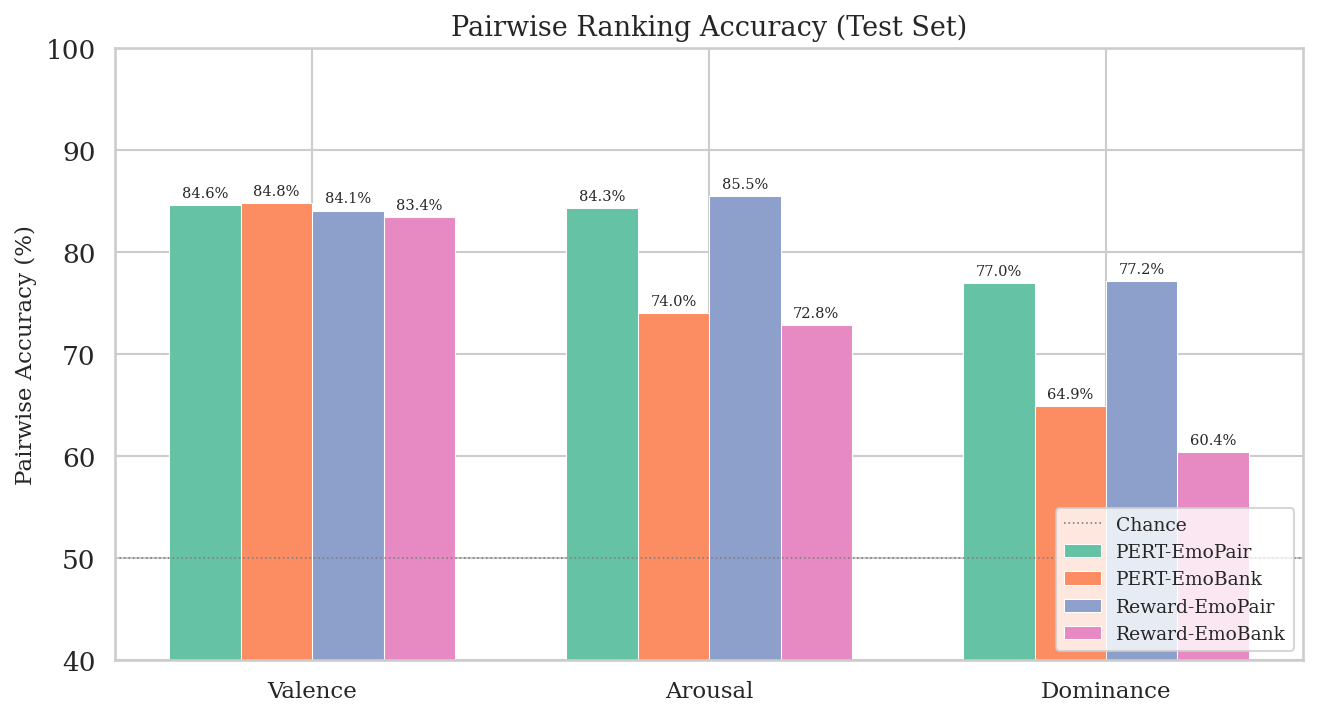

In [16]:
acc_cols = [c for c in pw_df.columns if "Acc" in c]
acc_plot = pw_df[acc_cols].copy()
acc_plot.columns = [c.replace(" Acc", "") for c in acc_cols]

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(acc_plot.columns))
width = 0.18
colors = sns.color_palette("Set2", 4)

for i, (name, color) in enumerate(zip(MODEL_NAMES, colors)):
    vals = acc_plot.loc[name].values
    offset = (i - 1.5) * width
    bars = ax.bar(x + offset, vals * 100, width, label=name, color=color, edgecolor="white", linewidth=0.5)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                f"{v:.1%}", ha="center", va="bottom", fontsize=7)

ax.axhline(50, color="grey", ls=":", lw=0.8, label="Chance")
ax.set_xticks(x)
ax.set_xticklabels(acc_plot.columns, fontsize=11)
ax.set_ylabel("Pairwise Accuracy (%)")
ax.set_ylim(40, 100)
ax.legend(fontsize=9, loc="lower right")
ax.set_title("Pairwise Ranking Accuracy (Test Set)")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "visuals" / "pairwise_accuracy_bar.pdf", bbox_inches="tight")
plt.show()

# 14 — Consolidated Summary Table (LaTeX-ready)
A single table combining all key metrics across all four models, suitable for inclusion in a publication.

In [ ]:

summary_rows = []
for name in MODEL_NAMES:
    pv = MODELS[name]["norm"]["valence"]
    raw = MODELS[name]["raw"]
    pa = raw["arousal"][bt_mask]
    pd_ = raw["dominance"][bt_mask]

    # Pairwise accuracy (recompute inline)
    acc_v = pairwise_accuracy_for_model(name, "valence")[2]
    acc_a = pairwise_accuracy_for_model(name, "arousal")[2]
    acc_d = pairwise_accuracy_for_model(name, "dominance")[2]

    summary_rows.append({
        "Model": name,
        # Valence pointwise
        "V MAE ↓":            mean_absolute_error(gold_V, pv),
        "V Pearson r ↑":      pearsonr(gold_V, pv)[0],
        # BT correlations (pairwise-derived scores)
        "A BT r ↑":           pearsonr(gold_A_bt[bt_mask], pa)[0],
        "D BT r ↑":           pearsonr(gold_D_bt[bt_mask], pd_)[0],
        # Original 1–5 score correlations
        "A orig r ↑":         pearsonr(gold_A, raw["arousal"])[0],
        "D orig r ↑":         pearsonr(gold_D, raw["dominance"])[0],
        # Pairwise accuracy
        "V Pair Acc ↑":       acc_v,
        "A Pair Acc ↑":       acc_a,
        "D Pair Acc ↑":       acc_d,
    })

summary = pd.DataFrame(summary_rows).set_index("Model")

# Display with highlighting
styled = summary.style.format("{:.4f}").highlight_min(
    subset=[c for c in summary.columns if "↓" in c], props="font-weight:bold"
).highlight_max(
    subset=[c for c in summary.columns if "↑" in c], props="font-weight:bold"
)
styled


,V MAE ↓,V Pearson r ↑,A BT r ↑,D BT r ↑,V Pair Acc ↑,A Pair Acc ↑,D Pair Acc ↑
Model,,,,,,,
PERT-EmoPair,0.1527,0.8338,0.8616,0.7313,0.8462,0.8434,0.7696
PERT-EmoBank,0.1442,0.8326,0.6144,0.4423,0.8479,0.7399,0.6493
Reward-EmoPair,0.3645,0.8200,0.8690,0.7294,0.8406,0.8550,0.7717
Reward-EmoBank,0.4849,0.7961,0.6283,0.2892,0.8343,0.7283,0.6036


In [ ]:

# Export LaTeX table
latex = summary.to_latex(
    float_format="%.4f",
    bold_rows=False,
    caption="Model comparison on the EmoPair test set. "
            "↑ = higher is better; ↓ = lower is better. "
            r"BT $r$ = Pearson correlation with Bradley-Terry scores; "
            r"orig $r$ = Pearson correlation with raw 1--5 annotator averages. "
            "Best in each column is bolded.",
    label="tab:model_comparison",
)

# Bold the best value in each column
lines = latex.split("\n")
print("\n".join(lines))

# Also save to file
with open(RESULTS_DIR / "visuals" / "model_comparison_table.tex", "w") as f:
    f.write(latex)
print(f"\nLaTeX table saved to Results/visuals/model_comparison_table.tex")


# 15 — Radar Chart: Per-Model Profile

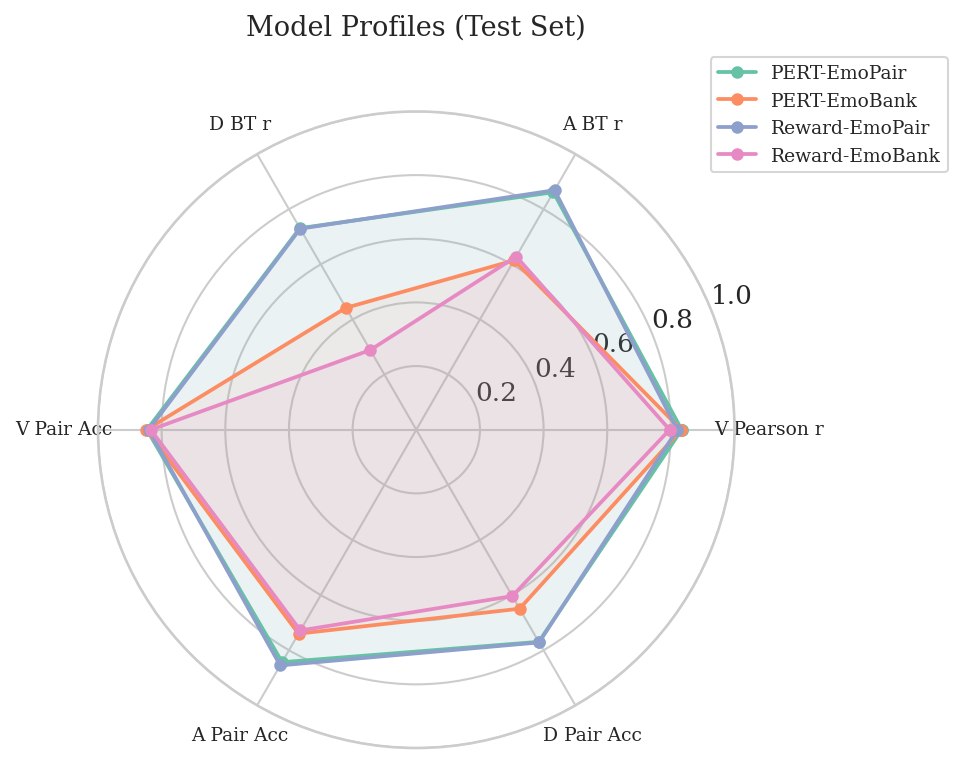

In [ ]:

# Radar chart: Pearson r across 3 dims (BT) + orig A/D r + pairwise accuracy for 3 dims = 8 axes
radar_metrics = [
    "V Pearson r ↑", "A BT r ↑", "D BT r ↑",
    "A orig r ↑", "D orig r ↑",
    "V Pair Acc ↑", "A Pair Acc ↑", "D Pair Acc ↑",
]
radar_labels = [
    "V Pearson r", "A BT r", "D BT r",
    "A orig r", "D orig r",
    "V Pair Acc", "A Pair Acc", "D Pair Acc",
]
n_metrics = len(radar_metrics)

angles = np.linspace(0, 2 * np.pi, n_metrics, endpoint=False).tolist()
angles += angles[:1]  # close the polygon

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
colors = sns.color_palette("Set2", 4)

for name, color in zip(MODEL_NAMES, colors):
    vals = [summary.loc[name, m] for m in radar_metrics]
    vals += vals[:1]
    ax.plot(angles, vals, "-o", color=color, label=name, lw=1.8, markersize=5)
    ax.fill(angles, vals, color=color, alpha=0.08)

ax.set_thetagrids(np.degrees(angles[:-1]), radar_labels, fontsize=9)
ax.set_ylim(0, 1)
ax.set_title("Model Profiles (Test Set)", fontsize=13, y=1.1)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1), fontsize=9)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "visuals" / "radar_model_comparison.pdf", bbox_inches="tight")
plt.show()


# 16 — Model Descriptions & Training Details

In [19]:
# Load training args for all four models
with open(pert_emopair_dir / "training_args.json") as f:
    args_pert_emopair = json.load(f)
with open(pert_emobank_dir / "training_args.json") as f:
    args_pert_emobank = json.load(f)
with open(MODELS_DIR / "emopair_reward_model_training_args_20260308.json") as f:
    args_rw_emopair = json.load(f)
with open(MODELS_DIR / "emobank_reward_model_training_args_20260308.json") as f:
    args_rw_emobank = json.load(f)

desc_rows = []
for name, args, arch, loss_desc in [
    ("PERT-EmoPair", args_pert_emopair,
     "RoBERTa-large → [CLS] → Linear(1024,3)",
     "MSE on V/A/D (A,D use BT scores)"),
    ("PERT-EmoBank", args_pert_emobank,
     "RoBERTa-large → [CLS] → Linear(1024,3)",
     "MSE on V/A/D (gold EmoBank labels)"),
    ("Reward-EmoPair", args_rw_emopair,
     "RoBERTa-large → [CLS] → V_head(1) + AD_head(2)",
     "V: MSE (pointwise) | A,D: BCE (pairwise, human annotations)"),
    ("Reward-EmoBank", args_rw_emobank,
     "RoBERTa-large → [CLS] → V_head(1) + AD_head(2)",
     "V: MSE (pointwise) | A,D: BCE (pairwise, EmoBank-derived)"),
]:
    lr = args.get("learning_rate", args.get("lr"))
    bs = args.get("effective_batch_size", args.get("batch_size"))
    epochs = args.get("num_epochs", args.get("epochs"))
    desc_rows.append({
        "Model": name,
        "Architecture": arch,
        "Loss": loss_desc,
        "LR": lr,
        "Eff. Batch": bs,
        "Epochs": epochs,
    })

desc_df = pd.DataFrame(desc_rows).set_index("Model")
desc_df

,Architecture,Loss,LR,Eff. Batch,Epochs
Model,,,,,
PERT-EmoPair,"RoBERTa-large → [CLS] → Linear(1024,3)","MSE on V/A/D (A,D use BT scores)",0.000030,16,15
PERT-EmoBank,"RoBERTa-large → [CLS] → Linear(1024,3)",MSE on V/A/D (gold EmoBank labels),0.000030,64,15
Reward-EmoPair,RoBERTa-large → [CLS] → V_head(1) + AD_head(2),"V: MSE (pointwise) | A,D: BCE (pairwise, human...",0.000002,64,20
Reward-EmoBank,RoBERTa-large → [CLS] → V_head(1) + AD_head(2),"V: MSE (pointwise) | A,D: BCE (pairwise, EmoBa...",0.000002,64,20


# 17 — Export All Results to CSV and Free up the GPU

In [ ]:

# Save all result tables
out_dir = RESULTS_DIR / "visuals"
out_dir.mkdir(exist_ok=True)

valence_df.to_csv(out_dir / "valence_regression_metrics.csv")
bt_df.to_csv(out_dir / "bt_correlation_metrics.csv")
pw_df.to_csv(out_dir / "pairwise_accuracy.csv")
summary.to_csv(out_dir / "model_comparison_summary.csv")
desc_df.to_csv(out_dir / "model_descriptions.csv")

# Save per-text predictions for downstream use
pred_df = test_items[["item_id", "text", "V", "A", "D"]].copy()
pred_df["A_BT"] = gold_A_bt
pred_df["D_BT"] = gold_D_bt
for name in MODEL_NAMES:
    tag = name.replace("-", "_").lower()
    pred_df[f"{tag}_V"] = MODELS[name]["norm"]["valence"]
    pred_df[f"{tag}_A"] = MODELS[name]["raw"]["arousal"]
    pred_df[f"{tag}_D"] = MODELS[name]["raw"]["dominance"]
pred_df.to_csv(out_dir / "all_model_test_predictions.csv", index=False)

print(f"All outputs saved to {out_dir}/")
print("Files:")
for f in sorted(out_dir.glob("*.csv")) + sorted(out_dir.glob("*.pdf")) + sorted(out_dir.glob("*.tex")):
    print(f"  {f.name}")


In [ ]:
# Free up the GPU
import gc
del pert_emopair, pert_emobank, rw_emopair, rw_emobank
gc.collect()
torch.cuda.empty_cache()
print("Done.")